<div align="center">

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fabianalexisbernabecruz-code/portafolio-actuaria-unam/blob/main/05_Quantitative_Finance_Fixed_Income.ipynb)
[![GitHub](https://img.shields.io/badge/GitHub-Repository-181717?logo=github)](https://github.com/fabianalexisbernabecruz-code/portafolio-actuaria-unam)

</div>



<font face="Times New Roman">

 <img src="https://upload.wikimedia.org/wikipedia/commons/c/ca/Escudo-UNAM-escalable.svg" width="150" height="170" align="left"/>

  <img src="https://upload.wikimedia.org/wikipedia/commons/5/5b/Escudo-facultad-ciencias-unam-escalable.svg" width="150" height="170" align="right"/>

<h5 align="center"><i> </i></h5>
<h1 align="center"><b>Valuación e Interpolación de Renta Fija</b></h1>
</font>
<font face="Times New Roman">

---
---

<h2 align="center"><i>Construcción de Curva Cupón Cero y Bootstrapping</i></h2>
<h5 align="center"><i>Implementación financiera para la valuación de bonos cuponados e interpolación de tasas.</i></h5>

---
---

<h5 align="center"><i>Universidad Nacional Autónoma de México</i></h5>
<h5 align="center"><i>Facultad de Ciencias — Actuaría</i></h5>
<h5 align="center"><i>Materia: Mercados Financieros y Valuación de Instrumentos</i></h5>

---
---

<font color="Black" face="Times New Roman">
<h5 align="center"><i>Bernabe Cruz Fabian Alexis</i></h5>

</font>
</font>

<font face="Times New Roman">


## 1. Esta sección busca evaluar tus conocimientos sobre programación para la construcción de una curva cupón cero.

<font face="Times New Roman">


### **(a) Interpolación lineal**.


<font face="Times New Roman">


Dada la siguiente curva que incluye bonos cupón cero (ZC) y bonos cuponados (BC), interpola linealmente los bonos que vencen en el plazo de 1 año, 3 años y 4 años. Programa esta sección con una función donde ingreses los nodos que quieres interpolar y la curva que se busca interpolar, y te regrese los bonos interpolados.

<div align="center">

| Plazo     | Tasa | Tipo Cupón |
|-----------|------|------------|
| 6 meses   | 10.2 | ZC         |
| 1.5 años  | 10.3 | BC         |
| 2 años    | 10.35| BC         |
| 2.5 años  | 10.40| BC         |
| 3.5 años  | 10.48| BC         |
| 5 años    | 10.50| BC         |

</div>

<font face="Times New Roman">

**Solución:**

</font>

In [ ]:
import pandas as pd

data = {'Plazo(años)': [0.5, 1.5, 2, 2.5, 3.5, 5],
        'Tasa yield': [10.2, 10.3, 10.35, 10.4, 10.48, 10.5],
        'Tipo de bono': ['ZC', 'BC', 'BC', 'BC', 'BC', 'BC']}
df = pd.DataFrame(data)

import sys
def _safe_input(prompt_text, default_val):
    """Permite entrada interactiva o utiliza valor predeterminado en entornos automáticos o si no hay entrada."""
    try:
        if not sys.stdin.isatty():
            return str(default_val)
        resp = input(f"{prompt_text} (Enter para default {default_val}): ").strip()
        return resp if resp else str(default_val)
    except (EOFError, OSError):
        return str(default_val)

tasacup = float(_safe_input('Ingrese la tasa cupón', 8.5))
Vnominal = float(_safe_input('Ingrese el valor nominal', 100.0))

def calcular_bono(año):
    for i in range(len(df['Plazo(años)'])):
        if año <= df['Plazo(años)'][i]:
            año2 = float(df['Plazo(años)'][i])
            año1 = float(df['Plazo(años)'][i-1]) if i > 0 else 0.0
            tasa2 = float(df['Tasa yield'][i])
            tasa1 = float(df['Tasa yield'][i-1]) if i > 0 else tasa2
            break
    else:
        año2 = float(df['Plazo(años)'].iloc[-1])
        año1 = float(df['Plazo(años)'].iloc[-2])
        tasa2 = float(df['Tasa yield'].iloc[-1])
        tasa1 = float(df['Tasa yield'].iloc[-2])

    denom = (año2 - año1) if (año2 - año1) != 0 else 1.0
    tasat = tasa1 + (año - año1) / denom * (tasa2 - tasa1)

    cupresent = sum((tasacup * 0.01 / 2) * Vnominal / ((1 + tasat * 0.01 / 2) ** k) for k in range(1, int(2 * año) + 1))
    Nominpresent = Vnominal / ((1 + tasat * 0.01 / 2) ** (2 * año))
    bonofin = cupresent + Nominpresent

    return tasat, bonofin

# Cantidad de plazos a interpolar
num_años = int(_safe_input('Ingrese la cantidad de años a calcular', 3))
defaults_anios = [1.0, 2.0, 3.0, 4.0, 5.0]
años_a_calcular = []
for i in range(num_años):
    def_a = defaults_anios[i] if i < len(defaults_anios) else float(i + 1)
    año = float(_safe_input(f'Ingrese el año {i+1}', def_a))
    años_a_calcular.append(año)

resultados = []
for año in años_a_calcular:
    tasat, bonofin = calcular_bono(año)
    tipo_bono = 'BC' if tasacup > 0 else 'ZC'
    resultados.append([año, tasat, tipo_bono, bonofin])

df_resultados = pd.DataFrame(resultados, columns=['Plazo(años)', 'Tasa yield', 'Tipo de bono', 'Precio del bono'])
df_resultados


<font face="Times New Roman">

---

</font>

<font face="Times New Roman">


### **(b) Bootstraping**.

<font face="Times New Roman">


Ahora considera la siguiente curva que contiene bonos cupón cero (ZC) y bonos cuponados (BC), aquí tu trabajo será crear una curva cupón cero. Tienes que generar una función que reciba una curva de rendimientos que puede contener cualquier tipo de bono (cero o cuponado) y además el tipo de cotización que se tiene para estos instrumentos (Actual/Actual o 30/360). Por otro lado, la función debe regresar la curva cupón cero. Grafica tus resultados.

<div align="center">

| Plazo     | Tasa | Tipo Cupón | Tasa Cupón |
|-----------|------|------------|------------|
| 6 meses   | 10.2 | ZC         | 0          |
| 1 año     | 10.3 | BC         | 8          |
| 2 años    | 10.35| BC         | 8          |
| 3.5 años  | 10.40| BC         | 8          |
| 5 años    | 10.50| BC         | 8          |


</div>


<font face="Times New Roman">

**Solución:**

</font>

<font face="Times New Roman">


Para utilizar el método de *bootstrapping* es necesario que los plazos de vencimiento de los cupones sean equidistantes, por ello utilizamos el inciso anterior para interpolar los bonos faltantes y obtener una curva que sí podamos usar para aplicar *bootstrapping* obteniendo con ello la siguiente tabla

<div align="center">

| Plazo     | Tasa     | Tipo Cupón | Tasa cupón |
|-----------|----------|------------|------------|
| 6 meses   | 10.200000| ZC         | 0          |
| 1 año     | 10.300000| BC         | 8          |
| 1.5 años  | 10.325000| BC         | 8          |
| 2 años    | 10.350000| BC         | 8          |
| 2.5 años  | 10.366667| BC         | 8          |
| 3 años    | 10.383333| BC         | 8          |
| 3.5 años  | 10.400000| BC         | 8          |
| 4 años    | 10.433333| BC         | 8          |
| 4.5 años  | 10.466667| BC         | 8          |
| 5 años    | 10.500000| BC         | 8          |

</div>

<font face="Times New Roman">

Para calcular la tasa cupón cero:

$$
TZ_{n} = \left( \frac{VN + C}{P - \sum_{i=1}^{n-1} \frac{C}{(1 + TZ_{i})^{i}}} \right)^{\frac{1}{n}} - 1, \quad n=2,3,\ldots
$$

</font>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Creamos la curva
curva = {
    'Plazo': ['6 meses', '1 año', '1.5 años', '2 años', '2.5 años', '3 años', '3.5 años', '4 años', '4.5 años', '5 años'],
    'Tasa': [10.200000, 10.300000, 10.325000, 10.350000, 10.366667, 10.383333, 10.400000, 10.433333, 10.466667, 10.500000],
    'Tipo Cupón': ['ZC', 'BC', 'BC', 'BC', 'BC', 'BC', 'BC', 'BC', 'BC', 'BC'],
    'Tasa cupón': [0, 8, 8, 8, 8, 8, 8, 8, 8, 8],
    'Plazo_num': [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
}

df_curva = pd.DataFrame(curva)

In [ ]:
# Para el método necesitamos los precios de cada bono, por lo que creamos una función que calcule el precio sucio.
def calcular_precio_sucio(nominal, tasa_cupon, plazo_num, tasa_descuento, tipo_cotizacion):
    '''
    Calcula el precio sucio de un bono, ya sea un bono cupón cero (ZC) o un bono con cupones (BC).

    Parámetros:
    - nominal (float): Valor nominal del bono.
    - tasa_cupon (float): Tasa de cupón anualizada del bono.
    - plazo_num (float): Plazo de vencimiento del bono (en años).
    - tasa_descuento (float): Tasa de descuento (Yield to Maturity) anualizada, utilizada para descontar los pagos futuros.

    Retorna:
    - precio (float): El precio sucio del bono.

    '''
    precio = 0
    # Tenemos dos casos; uno para cada tipo de cotización
    if tipo_cotizacion == "30/360":
        factor_tiempo = 180 / 360
    elif tipo_cotizacion == "Actual/Actual":
        factor_tiempo = 182 / 365
    else:
        raise ValueError("Tipo de cotización no válido. Use '30/360' o 'Actual/Actual'.")

    # Cálculo para bonos cupón cero (ZC) consideramos que es una tasa spot
    if tasa_cupon == 0:
        precio = nominal / (1 + (1 + tasa_descuento * factor_tiempo))**plazo_num
    else:  # Cálculo para bonos cuponados (BC)
        # obtenemos el cupón del bono
        cupon_periodo = (tasa_cupon) * nominal
        # iteramos para descontar cada cupón
        for i in range(1, int(plazo_num * 2) + 1):
            precio += cupon_periodo / (1 + tasa_descuento * factor_tiempo) ** (i * factor_tiempo)  # Ajustado para cupones semestrales
        # descontamos el valor nominal
        precio += nominal / (1 + tasa_descuento * factor_tiempo) ** plazo_num
    # regresamos el precio sucio del bono
    return precio

# El precio que obtenemos con la función de antes y los datos de la curva son
# suficientes para calcular cada nueva tasa cupón cero (TZ)

def calcular_tz(nominal, cupon_bono, precio_bono, plazo_num, tasas_cero_previas):
        '''
    Calcula la tasa cupón cero (TZ) de un bono en un plazo determinado utilizando el método de bootstraping.

    Parámetros:
    - nominal (float): Valor nominal del bono.
    - cupon_bono (float): Monto del cupón del bono.
    - precio_bono (float): Precio del bono.
    - plazo_num (float): Plazo de vencimiento del bono en años.
    - tasas_cero_previas (list): Lista de tasas cupón cero (TZ) previamente calculadas para bonos anteriores, usadas para descontar
      los pagos de cupones intermedios.

    Retorno:
    - tz (float): La nueva tasa cupón cero (TZ) para el bono en el plazo especificado, en decimales y semestral.

    '''
        # necesitamos descontar los cupones del bono usando ahora las tasas spot
        suma_descuentos = sum(cupon_bono / (1 + tasas_cero_previas[i])**df_curva.loc[i, 'Plazo_num']
                            for i in range(len(tasas_cero_previas)))
        # usamos la formula mencionada al inicio
        tz = ((nominal + cupon_bono) / (precio_bono - suma_descuentos)) ** (1 / plazo_num) - 1
        return tz

# Función principal para generar la curva cupón cero
def generar_curva_cupon_cero(curva_df, tipo_cotizacion):
    """
    Calcula la curva cupón cero para una serie de bonos, ajustando los precios y tasas
    según el tipo de cotización.

    Parámetros:
    -curva_df : pandas.DataFrame
        DataFrame con la curva de bonos, que incluye las columnas 'Tasa', 'Tasa cupón',
        'Plazo_num' y 'Tipo Cupón' ('ZC' para cupón cero).
    -tipo_cotizacion : str
        Tipo de cotización: '30/360' (cada mes de 30 días y año de 360) o 'Actual/Actual'.
    Retorno:
    pandas.DataFrame
        `curva_df` modificado con las columnas adicionales 'Precio' y 'Tasa Cupón Cero' y gráfica de la curva cupón cero.
    """
    nominal = 100  # Valor nominal estándar para los bonos
    tasas_cero = []

    for i, row in curva_df.iterrows():
        tasa_descuento = row['Tasa'] / 100
        precio_bono = calcular_precio_sucio(nominal, row['Tasa cupón'] / 100, row['Plazo_num'], tasa_descuento, tipo_cotizacion)

        if row['Tipo Cupón'] == 'ZC':
            tz = tasa_descuento / 2  # Tasa cupón cero directa para bonos ZC
        else:
            tz = calcular_tz(nominal, row['Tasa cupón'] / 100 * nominal, precio_bono, row['Plazo_num'], tasas_cero)

        tasas_cero.append(tz)
        curva_df.loc[i, 'Precio'] = precio_bono
        curva_df.loc[i, 'Tasa Cupón Cero'] = tz

    # Mostramos la tabla
    display(curva_df)

    # Graficamos la curva cupón cero
    plt.figure(figsize=(10, 6))
    plt.plot(curva_df['Plazo_num'], [tz * 100 for tz in curva_df['Tasa Cupón Cero']], marker='o', color='#1f77b4', linewidth=2)
    plt.xlabel('Plazo (años)', fontsize=12, fontweight='bold')
    plt.ylabel('Tasa Cupón Cero (%)', fontsize=12, fontweight='bold')
    plt.title('Curva Cupón Cero', fontsize=14, fontweight='bold')
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.grid(visible=True, linestyle='--', linewidth=0.5, alpha=0.7)
    plt.show()

    return curva_df

In [ ]:
# Aplicado a lo que queremos:
df_curva = pd.DataFrame(curva)
df_resultado = generar_curva_cupon_cero(df_curva, 'Actual/Actual')

<font face="Times New Roman">

## Comentarios Finales

</font>

<font face="Times New Roman">

Para validar el cálculo de la curva cupón cero, se replicó un ejemplo visto en clase, obteniendo los mismos resultados (el siguiente código se puede descomentar para verificarlo).

</font>

In [ ]:
'''
curva_Cristopher = {
    'Plazo': ['6 meses', '1 año', '1.5 años', '2 años', '2.5 años'],
    'Tasa': [10.7, 10.95, 11.1, 11.3, 11.5],
    'Tipo Cupón': ['ZC', 'BC', 'BC', 'BC', 'BC'],
    'Tasa cupón': [0, 9.85, 10, 10.5, 10.80],
    'Plazo_num': [0.5, 1.0, 1.5, 2.0, 2.5]
}
df_curva_Cristopher = pd.DataFrame(curva_Cristopher)
df_resultado = generar_curva_cupon_cero(df_curva_Cristopher, '30/360')
'''

<font face="Times New Roman">

---

</font>

<font face="Times New Roman">

## **Ejercicio 2.**

</font>

<font face="Times New Roman">

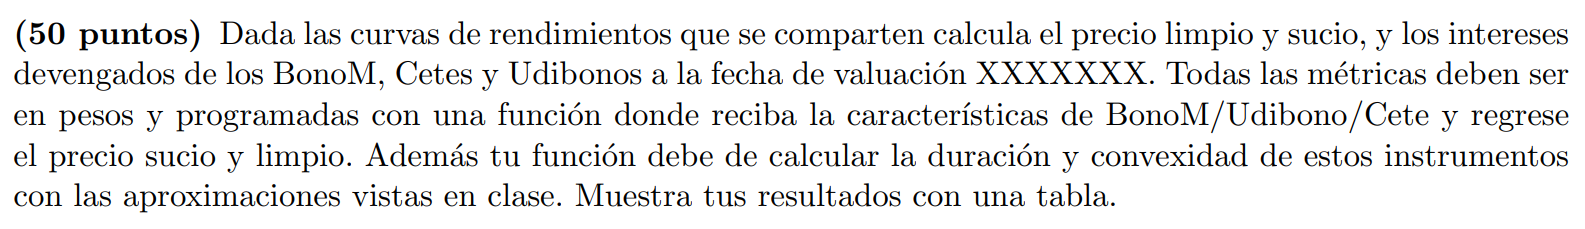

</font>

<font face="Times New Roman">

Primero creamos una conexión a una carpeta de Google Drive para tener acceso a los archivos CSV que contienen las características de los bonos que vamos a utilizar después.

</font>

In [ ]:
import requests
import pandas as pd
import os

# Conectar con Google Drive de manera opcional
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Google Drive montado exitosamente.')
except Exception:
    print('Aviso: Entorno sin Google Drive o montado omitido. Se usará el repositorio local/GitHub.')


<font face="Times New Roman">

A continuación creamos un DataFrame con los datos de las curvas de rendimiento almacenados en los archivos CSV previamente mencionados. Luego, en **df_mbonos**, **df_cetes** y **df_udibonos** se almacena únicamente la información necesaria para los cálculos requeridos.

**ES IMPORTANTE CAMBIAR LAS RUTAS DE Mbonos_curva, Cetes_curva, Udibonos_curva. Se debe copiar la ruta de cada curva (contenido en la carpeta anexada a esta entrega) respectivamente.**

</font>

In [ ]:
# DataFrame MBONOS
import pandas as pd
import os

def _cargar_curva_bono(nombre_archivo):
    rutas = [
        f'data/{nombre_archivo}',
        nombre_archivo,
        f'/content/ProyectoMercados/{nombre_archivo}',
        f'/content/{nombre_archivo}',
        f'https://raw.githubusercontent.com/fabianalexisbernabecruz-code/portafolio-actuaria-unam/main/data/{nombre_archivo}'
    ]
    for r in rutas:
        try:
            df_loaded = pd.read_csv(r)
            print(f'Cargado {nombre_archivo} desde: {r}')
            return df_loaded
        except Exception:
            pass
    raise FileNotFoundError(f'No se encontró {nombre_archivo}')

data1 = _cargar_curva_bono('MBONOS.csv')
df_mbonos = data1.copy()
if 'Instrumento' in df_mbonos.columns:
    df_mbonos = df_mbonos[['Instrumento','Serie','Fecha','DiasPorVencer','FechaInicioCupon','Rendimiento','TasaCuponVigente']]
    df_mbonos.columns = ['ID','FechaVencimiento','FechaValuacion','DiasPorVencer','UltimoCupon','Rendimiento','TasaCupon']
df_mbonos['FechaVencimiento'] = pd.to_datetime(df_mbonos['FechaVencimiento'], format='mixed')
df_mbonos['FechaValuacion'] = pd.to_datetime(df_mbonos['FechaValuacion'], format='mixed')
df_mbonos['UltimoCupon'] = pd.to_datetime(df_mbonos['UltimoCupon'], format='mixed')
if df_mbonos['Rendimiento'].max() > 1.0:
    df_mbonos['Rendimiento'] = df_mbonos['Rendimiento'] / 100
df_mbonos


In [ ]:
# DataFrame CETES
data2 = _cargar_curva_bono('CETES.csv')
df_cetes = data2.copy()
if 'Instrumento' in df_cetes.columns:
    df_cetes = df_cetes[['Instrumento','Serie','Fecha','DiasPorVencer','FechaInicioCupon','Rendimiento','TasaCuponVigente']]
    df_cetes.columns = ['ID','FechaVencimiento','FechaValuacion','DiasPorVencer','UltimoCupon','Rendimiento','TasaCupon']
df_cetes['FechaVencimiento'] = pd.to_datetime(df_cetes['FechaVencimiento'], format='mixed')
df_cetes['FechaValuacion'] = pd.to_datetime(df_cetes['FechaValuacion'], format='mixed')
df_cetes['UltimoCupon'] = pd.to_datetime(df_cetes['UltimoCupon'], format='mixed')
if df_cetes['Rendimiento'].max() > 1.0:
    df_cetes['Rendimiento'] = df_cetes['Rendimiento'] / 100
df_cetes


<font face="Times New Roman">

Para los Udibonos definimos la función **obtener_udi_actual**, que consulta en la página de Banxico el valor de la udi a la fecha de valuación para después poder obtener el equivalente del precio sucio, precio limpio e intereses devengados en pesos mexicanos.

</font>

In [ ]:
# DataFrame UDIBONOS
data3 = _cargar_curva_bono('UDIBONOS.csv')
df_udibonos = data3.copy()
if 'Instrumento' in df_udibonos.columns:
    df_udibonos = df_udibonos[['Instrumento','Serie','Fecha','DiasPorVencer','FechaInicioCupon','Rendimiento','TasaCuponVigente']]
    df_udibonos.columns = ['ID','FechaVencimiento','FechaValuacion','DiasPorVencer','UltimoCupon','Rendimiento','TasaCupon']
df_udibonos['FechaVencimiento'] = pd.to_datetime(df_udibonos['FechaVencimiento'], format='mixed')
df_udibonos['FechaValuacion'] = pd.to_datetime(df_udibonos['FechaValuacion'], format='mixed')
df_udibonos['UltimoCupon'] = pd.to_datetime(df_udibonos['UltimoCupon'], format='mixed')
if df_udibonos['Rendimiento'].max() > 1.0:
    df_udibonos['Rendimiento'] = df_udibonos['Rendimiento'] / 100

# Función para obtener el valor de la UDI con fallback si no hay conexión
def obtener_udi_actual(api_key, date):
    headers = {'Bmx-Token': api_key}
    udi_series_id = 'SP68257'
    url = f'https://www.banxico.org.mx/SieAPIRest/service/v1/series/{udi_series_id}/datos/{date}/{date}'
    try:
        respuesta = requests.get(url, headers=headers, timeout=5)
        if respuesta.status_code == 200:
            datos = respuesta.json()
            return float(datos['bmx']['series'][0]['datos'][0]['dato'])
    except Exception as e:
        print(f'Aviso: Banxico API no accesible ({e}). Usando valor UDI de referencia.')
    return 8.2587

df_udibonos


<font face="Times New Roman">

La fecha de valuación predeterminada para los bonos es el 25/10/2024.

**Si se desea cambiar la fecha de valuación se debe ejecutar el siguiente bloque de código:**

</font>

In [ ]:
def _safe_input_date(prompt_text, default_val='25/10/2024'):
    try:
        if not sys.stdin.isatty():
            return str(default_val)
        resp = input(f"{prompt_text} (Enter para default {default_val}): ").strip()
        return resp if resp else default_val
    except (EOFError, OSError):
        return default_val

fecha_valuacion_str = _safe_input_date('Ingresa la fecha de valuación (dd/mm/yyyy)')

while True:
    try:
        nueva_fecha_valuacion = pd.to_datetime(fecha_valuacion_str, format='%d/%m/%Y')
        break
    except ValueError:
        print('Fecha inválida. Utilizando fecha por defecto 25/10/2024.')
        nueva_fecha_valuacion = pd.to_datetime('25/10/2024', format='%d/%m/%Y')
        break

df_mbonos['FechaValuacion'] = nueva_fecha_valuacion
df_cetes['FechaValuacion'] = nueva_fecha_valuacion
df_udibonos['FechaValuacion'] = nueva_fecha_valuacion
print('Fecha de valuación fijada en:', nueva_fecha_valuacion.strftime('%Y-%m-%d'))


<font face="Times New Roman">

A continuación se define la función **info_bono** que toma como argumentos la fecha del último pago cupón, la fecha de valuación, el plazo a vencimiento, la tasa de rendimiento (YTM) y la tasa cupón del bono y retorna un diccionario con los resultados. Las fórmulas de valuación se detallan en el reporte anexado.

</font>

In [ ]:
from datetime import datetime
import pandas as pd
import math

def info_bono(instrumento, fecha_ultimo_pago, fecha_valuacion, plazo_vencer, tasa_rendimiento, tasa_cupon):
    """
    Calcula el precio limpio, precio sucio, intereses devengados, duración y convexidad de un bono.

    Args:
    - fecha_ultimo_pago (str): Fecha del último pago en formato AAAA/MM/DD.
    - fecha_valuacion (str): Fecha de valuación en formato AAAA/MM/DD.
    - plazo_vencer (int): Plazo del vencimiento del bono en días.
    - tasa_rendimiento (float): Tasa de rendimiento del mercado anual.
    - tasa_cupon (float): Tasa de cupón anual.

    Returns:
    - dict: Diccionario con precio limpio, precio sucio, intereses devengados, duración y covexidad.
    """

    #Establecemos el periodo de pago y valor nominal dependiendo del tipo de instrumento:
    if (instrumento.startswith('M_BONOS') or instrumento.startswith('S_UDIBONO')):
      periodo_pago = 182  # Semestral
      valor_nominal = 100
    elif instrumento.startswith('BI_CETES'):
      periodo_pago = plazo_vencer
      fecha_ultimo_pago = fecha_valuacion
      valor_nominal = 10

    # Calcular el número de cupones por pagar
    cupones_restantes = math.ceil(plazo_vencer / periodo_pago)

    # Calcular el número de días desde el último pago
    dias_transcurridos = (fecha_valuacion - fecha_ultimo_pago).days

    # Calcular pago de cupón
    cupon_periodo = valor_nominal * tasa_cupon * (periodo_pago / 360) #usando actual/360

    # Calcular intereses devengados
    intereses_devengados = cupon_periodo * (dias_transcurridos / periodo_pago)

    # Calcular el valor presente a la fecha del último pago:
    valor_presente = sum(cupon_periodo / (1 + tasa_rendimiento * (periodo_pago / 360) ) ** t for t in range(1, cupones_restantes + 1)) #Descontamos los flujos
    valor_presente += valor_nominal / (1 + tasa_rendimiento * (periodo_pago / 360)) ** cupones_restantes # Flujos descontados + valor presente del valor nominal

    # Calcular el precio sucio:
    precio_sucio = valor_presente * (1 + (tasa_rendimiento * (periodo_pago / 360))) ** (dias_transcurridos / periodo_pago)

    # Calcular el precio limpio:
    precio_limpio = precio_sucio - intereses_devengados

    # Si el instrumento es un udibono es necesario consultar el valor de la udi a la fecha de valuación
    if instrumento.startswith('S_UDIBONO'):
      # Obtenemos el valor actual de la UDI desde la API (para una única fecha)
      api_key = '475fb78a5e6dce0784c4c41950a367caf81b321c9cea3f455286de7771862ef2'
      Udi_actual = obtener_udi_actual(api_key, fecha_valuacion.strftime('%Y-%m-%d'))
      precio_limpio = precio_limpio*Udi_actual
      precio_sucio = precio_sucio*Udi_actual
      intereses_devengados = intereses_devengados*Udi_actual

    # Cálculo de Duración de Macaulay
    num_dur = sum((t*cupon_periodo) / (1 + tasa_rendimiento * (periodo_pago / 360) ) ** t for t in range(1, cupones_restantes + 1))
    num_dur += (cupones_restantes*valor_nominal) / (1 + tasa_rendimiento * (periodo_pago / 360)) ** cupones_restantes
    den_dur = valor_presente*(360/periodo_pago)
    dur_mac = num_dur/den_dur

    # Cálculo de Duración Modificada
    dmod=dur_mac/(1+tasa_rendimiento*(periodo_pago/360))

    # Cálculo de Convexidad
    a_conv=1/valor_presente
    b_conv=1/(1+tasa_rendimiento*(periodo_pago/360))**2
    c_conv = sum((t*(t+1)*cupon_periodo) / (1 + tasa_rendimiento * (periodo_pago/ 360) ) ** t for t in range(1, cupones_restantes + 1))
    c_conv += (cupones_restantes*(cupones_restantes+1)*valor_nominal) / (1 + tasa_rendimiento * (periodo_pago / 360)) ** cupones_restantes
    conv = a_conv*b_conv*c_conv

    #Retornamos los resultados obtenidos con 6 decimales
    return {
        "precio_sucio": f"{precio_sucio:.6f}",
        "precio_limpio": f"{precio_limpio:.6f}",
        "intereses_devengados": f"{intereses_devengados:.6f}",
        "duración_modificada": f"{dmod:.6f}",
        "convexidad": f"{conv:.6f}"
    }

<font face="Times New Roman">

Para cada tipo de bono se crea una tabla con el cálculo del precio sucio, precio limpio, intereses devengados, duración modificada y convexidad realizado por la función anterior. Notese que para acceder al valor correspondiente que se introduce como argumentos en la función se hace uso de los DataFrames previamente definidos.

Para ver la tabla con los resultados por tipo de bono se debe imprimir **df_resultados_mbonos**, **df_resultados_cetes** o **df-resultados_udibonos**, según sea el caso.

Los cálculos del precio sucio, precio limpio e intereses devengados mostrados a continuación coinciden con los de las curvas de rendimiento originales, indicando que el cálculo es correcto.

</font>

In [ ]:
#Resultado MBONOS
resultados_mbonos = []
for id, row in df_mbonos.iterrows():
    resultado = info_bono(
        instrumento=row['ID'],
        fecha_ultimo_pago=row['UltimoCupon'],
        fecha_valuacion=row['FechaValuacion'],
        plazo_vencer=row['DiasPorVencer'],
        tasa_rendimiento=row['Rendimiento'],
        tasa_cupon=row['TasaCupon'],
    )
    resultados_mbonos.append(resultado)

# Crear un DataFrame con los resultados
df_resultados_mbonos = pd.DataFrame(resultados_mbonos, index=df_mbonos['ID'])
df_resultados_mbonos.columns = ['Precio Sucio (MXN)','Precio Limpio (MXN)','Intereses Devengados (MXN)', "Duración Modificada", "Convexidad"]
print("Fecha de Valuación: ",df_mbonos["FechaValuacion"][0])
df_resultados_mbonos

In [ ]:
#Resultado CETES
#Creamos una lista que contendrá los resultados
resultados_cetes = []
for id, row in df_cetes.iterrows():
    resultado = info_bono(
        instrumento=row['ID'],
        fecha_ultimo_pago=row['UltimoCupon'],
        fecha_valuacion=row['FechaValuacion'],
        plazo_vencer=row['DiasPorVencer'],
        tasa_rendimiento=row['Rendimiento'],
        tasa_cupon=row['TasaCupon'],
    )
    resultados_cetes.append(resultado)

# Crear un DataFrame con los resultados
df_resultados_cetes = pd.DataFrame(resultados_cetes, index=df_cetes['ID'])
df_resultados_cetes.columns = ['Precio Sucio (MXN)','Precio Limpio (MXN)','Intereses Devengados (MXN)', "Duración Modificada", "Convexidad"]
print("Fecha de Valuación: ",df_cetes["FechaValuacion"][0])
df_resultados_cetes

In [ ]:
#Resultado UDIBONOS
#Creamos una lista que contendrá los resultados
resultados_udibonos = []
for id, row in df_udibonos.iterrows():
    resultado = info_bono(
        instrumento=row['ID'],
        fecha_ultimo_pago=row['UltimoCupon'],
        fecha_valuacion=row['FechaValuacion'],
        plazo_vencer=row['DiasPorVencer'],
        tasa_rendimiento=row['Rendimiento'],
        tasa_cupon=row['TasaCupon'],
    )
    resultados_udibonos.append(resultado)

# Crear un DataFrame con los resultados
df_resultados_udibonos = pd.DataFrame(resultados_udibonos, index=df_udibonos['ID'])
df_resultados_udibonos.columns = ['Precio Sucio (MXN)','Precio Limpio (MXN)','Intereses Devengados (MXN)', "Duración Modificada", "Convexidad"]
print("Fecha de Valuación: ",df_udibonos["FechaValuacion"][0])
df_resultados_udibonos

<font face="Times New Roman">

Para ver los resultados obtenidos para todos los bonos, se debe imprimir **df_resultados**

</font>

In [ ]:
# Unir las tablas
df_resultados = pd.concat([df_resultados_mbonos, df_resultados_cetes, df_resultados_udibonos])

#DataFrame con el resultado final
df_resultados

<font face="Times New Roman">

## Comentarios Finales

</font>

<font face="Times New Roman">

Para validar el cálculo de duración y convexidad en la función `info_bono`, se replicó un ejemplo visto en clase, obteniendo los mismos resultados (el siguiente código se puede descomentar para verificarlo), lo cual confirma la precisión del código implementado. Sin embargo, la duración que coincide con las curvas de rendimiento proporcionadas corresponde solo a los CETES; en el caso de los MBONOS y UDIBONOS, la duración y convexidad calculadas difieren de los valores mostrados en el archivo compartido. Nos indicaron que esta discrepancia no representa un problema, ya que probablemente los métodos empleados para obtener dichos resultados difieren de los vistos en clase.

</font>

In [ ]:

'''
Ejemplo visto en clase:

vn=100
pago_cupon=2
plazo=182
ytm=4.2/100

valor_presente = sum(pago_cupon / (1 + ytm * (plazo / 364) ) ** t for t in range(1, 6 + 1))
valor_presente += vn / (1 + ytm * (plazo / 364)) ** 6

# Cálculo de duración macaulay
num_dur = sum((t*pago_cupon) / (1 + ytm * (plazo/ 364) ) ** t for t in range(1, 6 + 1))
num_dur += (6*vn) / (1 + ytm * (plazo / 364)) ** 6
den_dur = valor_presente*(364/plazo)
dur = num_dur/den_dur
print("Duración Macaulay: ", round(dur,3))

#Duración modificada
dmod=dur/(1+ytm*(plazo/364))
print("Duración Modificada:", round(dmod,3)) #Mismo fresultado para la duración

#Convexidad
a_conv=1/valor_presente
b_conv=1/(1+ytm*(plazo/364))**2

c_conv = sum((t*(t+1)*pago_cupon) / (1 + ytm * (plazo/ 364) ) ** t for t in range(1, 6 + 1))
c_conv += (6*7*vn) / (1 + ytm * (plazo / 364)) ** 6

conv=a_conv*b_conv*c_conv
print("Convexidad:", round(conv,3)) #Mismo resultado para la convexidad
'''